# 07 — Robustness Checks
**Stage:** Evaluation

**TL;DR:** > **Final answer in Notebook 08:** official sales by customer type show the failed monsoon was the main cause (pump sets 69% of the FY24 increase, households 13%).

 Faster-trend, placebo and flagged-day tests hold. **Two natural experiments bracket the drought share only loosely:** 2016 (drought, no scheme: +16.7% above expected vs 2023's +21.5%) gives the **upper end, ~78%**; 2024 (scheme, normal rain), measured **rain-adjusted** (+16.4% above expected after removing its extra rain), gives the **lower end, ~24%**. *(An earlier version gave 43% by mistake: it counted wet 2024's weather as part of the 2023 drought.)* So the **failed monsoon explains roughly 24–78%** of the Aug–Oct 2023 surge, and the data **cannot show which cause was larger**. Two things are robust: a drought alone (2016) produced a jump nearly as large as 2023's, and a **lasting +14–17% increase** above the rain-aware model started in August 2023 and was still there in 2024 and 2025 — in every model version tested.

## 1. Question
Can we **break** the findings of Notebooks 05–06? (Riley: "be both skeptic and champion"; Card & Krueger: placebo
tests and a second natural experiment.)

Findings under test (Aug–Oct 2023, excess ≈ 1,860 MW over the calendar + heat + trend model):
- failed monsoon ≈ 445–664 MW (24–36%), free electricity ≤ 238 MW (≤ 13%), "other" lasting ≈ 958–1,414 MW.

| # | Test | The finding would break if… |
|---|---|---|
| 1 | Faster growth trend (4–8%/yr instead of 2.96%) | the "other" part disappears with a plausible trend |
| 2 | Placebo start dates (1 Aug 2021, 2022; 2015) | the method finds a large "effect" in years with no event |
| 3 | Drop the 8 flagged days (Notebook 02) | the numbers change noticeably |
| 4 | **2016**: equally dry, **no** free electricity | a drought alone produces the same pattern → our drought share is too low |

## 2. Expectation *(written before running)*
1. A faster trend will shrink the "other" part somewhat, but the trend only acts for ~0.7 years after training ends,
   so it should not remove a ~1,400 MW step.
2. Placebo years should show gaps within the model's normal error (±4% monthly, ~±8% for 2 std).
3. Dropping the flagged days should change almost nothing (they are in Oct–Nov, the 2023 gap is in Aug–Oct).
4. **2016 is the real test.** If 2016 shows a large excess beyond what the rain model explains, then our models
   underestimate full-season drought effects, and some of 2023's "other" is really drought.

## 3. Data used
Same features and models as Notebook 05 (`src/features.py`, `src/model.py`). For 2015–2017 the models are trained
on **2011 → year−1** (2011–2012 are the least reliable years, see Notebook 02; 2011–2013 were also years of
power shortage, with grid frequency below 49.9 Hz in 31–77% of hours, against ~2% in 2016, and this model has no
backtest of its own). The 30-day rain anomaly regression is
the same as Notebook 06.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from src import config, plots, features as F, model as M

plots.setup()
pd.set_option("display.width", 200)
P = config.DATA_PROCESSED
df = F.build_hourly_frame(pd.read_parquet(P / "load_hourly.parquet"), pd.read_parquet(P / "weather_daily.parquet"),
                          pd.read_parquet(P / "weather_hourly_blr.parquet"), pd.read_parquet(P / "holidays.parquet"))
FEAT_A = F.CALENDAR_FEATURES + F.TEMP_FEATURES
FEAT_B = FEAT_A + F.RAIN_FEATURES


def fit_pair(train_start, train_end, growth=None):
    mA = M.CounterfactualModel(FEAT_A, fixed_growth=growth).fit(df, train_start, train_end)
    mB = M.CounterfactualModel(FEAT_B, fixed_growth=growth).fit(df, train_start, train_end)
    return mA, mB


def evaluate(mA, mB, yr, drop_days=None):
    """Aug–Oct decomposition for one year (same definitions as Notebooks 05–06)."""
    p = df.loc[f"{yr}-08-01":f"{yr}-12-31"].dropna(subset=["load_mw"] + FEAT_B).copy()
    if drop_days is not None:
        p = p[~p.index.normalize().isin(drop_days)]
    p["A"], p["B"] = mA.predict(p).values, mB.predict(p).values
    w = p.loc[f"{yr}-08-01":f"{yr}-10-31"]
    base = w.A.mean()
    dd = p[["load_mw", "A", "rain_30d_anom"]].resample("D").mean().dropna()
    dd["gap_A_%"] = (dd.load_mw / dd.A - 1) * 100
    r = sm.OLS(dd["gap_A_%"], sm.add_constant(dd.rain_30d_anom / 100)).fit()
    anom_aug_oct = dd.loc[f"{yr}-08-01":f"{yr}-10-31"].rain_30d_anom.mean()
    return {"year": yr, "trend %/yr": mA.trend.growth_per_year * 100, "expected MW": base,
            "total excess MW": w.load_mw.mean() - base, "total excess %": (w.load_mw.mean() / base - 1) * 100,
            "rain effect, Model B (MW)": w.B.mean() - base,
            "rain effect, regression (MW)": r.params.iloc[1] * anom_aug_oct / 100 / 100 * base,
            "unexplained vs B (MW)": w.load_mw.mean() - w.B.mean(),
            "unexplained vs B %": (w.load_mw.mean() / w.B.mean() - 1) * 100}


base_A, base_B = fit_pair("2015-01-01", "2022-12-31 23:00")
main = evaluate(base_A, base_B, 2023)
pd.Series(main).round(1).to_frame("2023 main result")

,2023 main result
year,2023.0
trend %/yr,3.0
expected MW,8640.0
total excess MW,1859.5
total excess %,21.5
"rain effect, Model B (MW)",445.1
"rain effect, regression (MW)",513.5
unexplained vs B (MW),1414.4
unexplained vs B %,15.6


## 4. Analysis
### Test 1 — Faster growth trend
*Why:* if demand was simply growing faster after 2022 than the 2011–2022 trend (2.96%/yr), the "other" part could be
ordinary growth. Re-run everything with the trend forced to 4%, 5%, 6% and 8% per year.

In [2]:
rows = [dict(main, **{"assumed growth": "fitted (2.96%)"})]
for g in [0.04, 0.05, 0.06, 0.08]:
    mA, mB = fit_pair("2015-01-01", "2022-12-31 23:00", growth=g)
    rows.append(dict(evaluate(mA, mB, 2023), **{"assumed growth": f"{g:.0%}"}))
t1 = pd.DataFrame(rows).set_index("assumed growth")[["total excess MW", "rain effect, Model B (MW)",
                                                     "rain effect, regression (MW)", "unexplained vs B (MW)", "unexplained vs B %"]]
t1.round(0)

,total excess MW,"rain effect, Model B (MW)","rain effect, regression (MW)",unexplained vs B (MW),unexplained vs B %
assumed growth,,,,,
fitted (2.96%),1860.0,445.0,513.0,1414.0,16.0
4%,1745.0,468.0,498.0,1276.0,14.0
5%,1620.0,400.0,500.0,1220.0,13.0
6%,1586.0,435.0,521.0,1151.0,12.0
8%,1501.0,685.0,545.0,816.0,8.0


_What I see:_ even with the trend **doubled to 6%/yr**, ~1,150 MW stays unexplained. Faster growth can only explain
a few hundred MW, because the trend acts for less than a year after training ends.

### Test 2 — Placebo start dates
*Why:* run the identical method on years when **nothing happened** (no scheme). If it finds a big gap there too,
the method — not the event — is creating the effect.

In [3]:
plac = []
for yr, start in [(2015, "2011-01-01"), (2021, "2015-01-01"), (2022, "2015-01-01")]:
    mA, mB = fit_pair(start, f"{yr - 1}-12-31 23:00")
    plac.append(evaluate(mA, mB, yr))
plac.append(main)
t2 = pd.DataFrame(plac).set_index("year")[["total excess %", "unexplained vs B %", "unexplained vs B (MW)"]]
t2.round(1)

,total excess %,unexplained vs B %,unexplained vs B (MW)
year,,,
2015,-1.6,-3.4,-221.8
2021,10.0,4.4,322.4
2022,-4.7,-4.5,-342.1
2023,21.5,15.6,1414.4


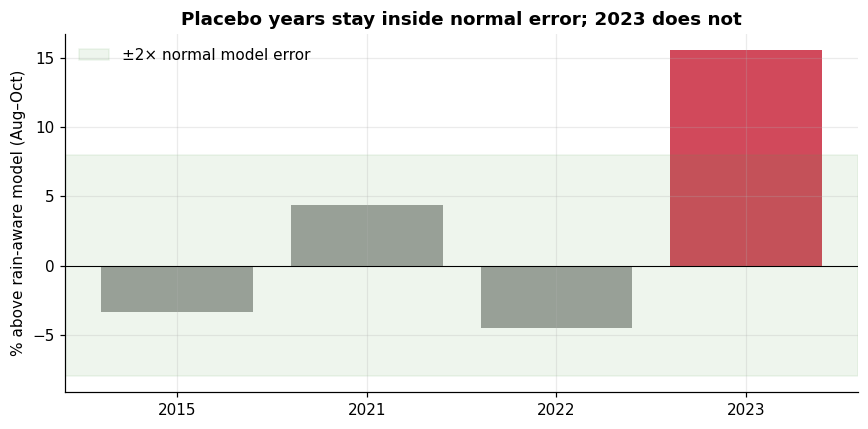

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = [plots.COLORS["muted"]] * 3 + [plots.COLORS["highlight"]]
ax.bar(t2.index.astype(str), t2["unexplained vs B %"], color=colors)
ax.axhspan(-8, 8, color="#59a14f", alpha=0.1, label="±2× normal model error")
ax.axhline(0, color="black", lw=0.7)
ax.set_ylabel("% above rain-aware model (Aug–Oct)")
ax.set_title("Placebo years stay inside normal error; 2023 does not")
ax.legend(); plt.tight_layout(); plots.save(fig, "07_placebo"); plt.show()

### Test 3 — Drop the flagged days
*Why:* Notebook 02 flagged 8 days in Oct–Nov 2023 where hourly data and the daily total disagree by >3%.

In [5]:
flags = pd.read_parquet(P / "daily_crosscheck.parquet")
bad = flags.index[flags.xcheck_flag]
t3 = pd.DataFrame([main, evaluate(base_A, base_B, 2023, drop_days=bad)], index=["all days", "flagged days removed"])
t3[["total excess MW", "rain effect, Model B (MW)", "unexplained vs B (MW)"]].round(0)

,total excess MW,"rain effect, Model B (MW)",unexplained vs B (MW)
all days,1860.0,445.0,1414.0
flagged days removed,1866.0,453.0,1414.0


### Test 4 — 2016: a drought year without free electricity
*Why:* Aug–Oct 2016 farm-belt rain was **250 mm** (2023: 256 mm) and there was **no Gruha Jyothi**. If the method
finds a similar "unexplained" excess in 2016, that excess must be drought (or something else), not the scheme.
2017 had normal rain, so it shows whether the 2016 excess persisted.

In [6]:
mA16, mB16 = fit_pair("2011-01-01", "2015-12-31 23:00")
t4 = pd.DataFrame([evaluate(mA16, mB16, 2016), evaluate(mA16, mB16, 2017), main, evaluate(base_A, base_B, 2024)]).set_index("year")
t4.insert(0, "situation", ["drought, no scheme", "normal rain, no scheme", "drought + scheme", "normal rain + scheme"])
t4[["situation", "total excess %", "total excess MW", "rain effect, Model B (MW)", "unexplained vs B %", "unexplained vs B (MW)"]].round(1)

,situation,total excess %,total excess MW,"rain effect, Model B (MW)",unexplained vs B %,unexplained vs B (MW)
year,,,,,,
2016,"drought, no scheme",16.7,1080.0,162.8,13.8,917.2
2017,"normal rain, no scheme",-2.4,-161.2,10.4,-2.6,-171.6
2023,drought + scheme,21.5,1859.5,445.1,15.6,1414.4
2024,normal rain + scheme,12.3,1003.0,-330.2,17.1,1333.2


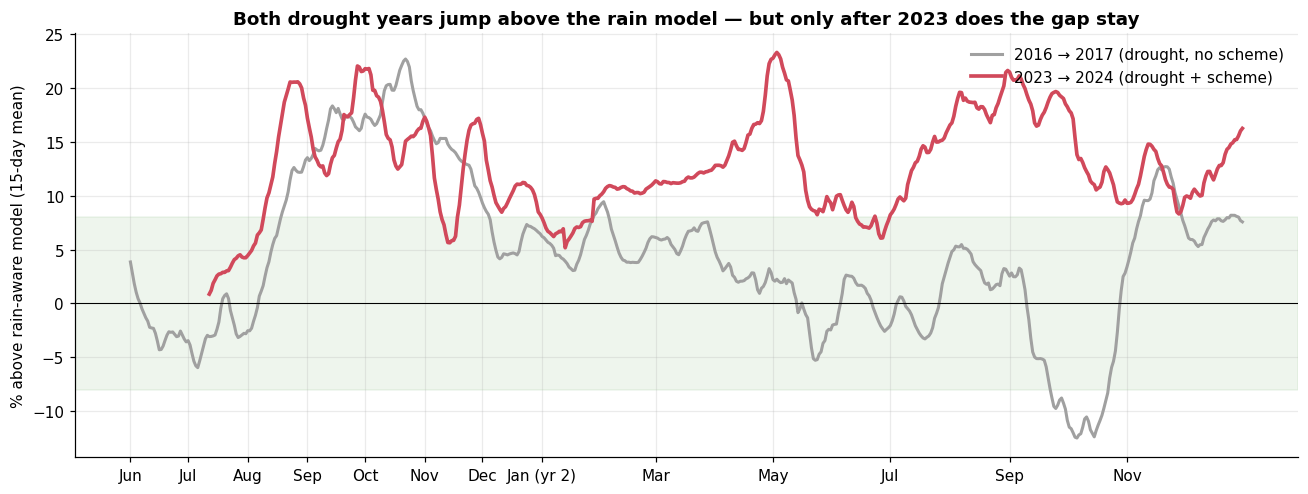

In [7]:
def gap_series(mB, start, end):
    p = df.loc[start:end].dropna(subset=["load_mw"] + FEAT_B)
    s = (p.load_mw / mB.predict(p).values - 1) * 100
    return s.resample("D").mean().rolling(15, center=True, min_periods=7).mean()

g16 = gap_series(mB16, "2016-06-01", "2017-12-31")
g23 = gap_series(base_B, "2023-07-13", "2024-12-31")
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot((g16.index - pd.Timestamp("2016-01-01")).days, g16.values, color=plots.COLORS["muted"], lw=2, label="2016 → 2017 (drought, no scheme)")
ax.plot((g23.index - pd.Timestamp("2023-01-01")).days, g23.values, color=plots.COLORS["highlight"], lw=2.4, label="2023 → 2024 (drought + scheme)")
ax.axhspan(-8, 8, color="#59a14f", alpha=0.1)
ax.axhline(0, color="black", lw=0.7)
ticks = [pd.Timestamp(f"2016-{m:02d}-01") for m in range(6, 13)] + [pd.Timestamp(f"2017-{m:02d}-01") for m in range(1, 13, 2)]
ax.set_xticks([(t - pd.Timestamp("2016-01-01")).days for t in ticks],
              [t.strftime("%b") + (" (yr 2)" if t.year == 2017 and t.month == 1 else "") for t in ticks])
ax.set_ylabel("% above rain-aware model (15-day mean)")
ax.set_title("Both drought years jump above the rain model — but only after 2023 does the gap stay")
ax.legend(loc="upper right"); plt.tight_layout(); plots.save(fig, "07_2016_vs_2023"); plt.show()

_What I see:_ the 2016 drought (no scheme) also rose far above the rain-aware model — so **the models underestimate
what a full-season drought does**. After 2016 the gap **fell back to normal** in 2017; after 2023 it **stayed high**
through 2024.

### Step 4.5 — When did the lasting increase appear? Does it include household hours?
*Why (added after external review):* 2024 had normal rain and was still well above expected. If that lasting
increase was already present in Aug–Oct 2023, part of the 2023 surge belongs to it, not to the drought.

**Two measures, used throughout this notebook — do not mix them:**
- **"excess over Model A"** = demand above the model *without* rain (calendar + heat + trend). Contains the drought.
- **"excess over Model B"** = demand above the model *with* rain. The drought is (partly) removed.
For Aug–Oct 2023 these are **+21.5%** and **+15.6%** respectively.

In [8]:
cf = pd.read_parquet(P / "counterfactual_hourly.parquet")       # Notebook 05 predictions (same models)
mon = cf.groupby([cf.index.year, cf.index.month])[["load_mw", "pred_A", "pred_B"]].mean()
mon["excess over A %"] = (mon.load_mw / mon.pred_A - 1) * 100
mon["excess over B %"] = (mon.load_mw / mon.pred_B - 1) * 100
mon.index.names = ["year", "month"]
print("Monthly excess, Jul 2023 – Jun 2024 (normal band for Model B: about ±4%, ±8% at 2 std):")
mon.loc[(2023, 7):(2024, 6), ["excess over A %", "excess over B %"]].round(1).T

Monthly excess, Jul 2023 – Jun 2024 (normal band for Model B: about ±4%, ±8% at 2 std):


year            2023                               2024                             
month             7     8     9     10    11    12   1     2     3     4     5    6 
excess over A %  8.9  24.8  22.2  17.9   8.1  12.3  7.8  10.0  12.7  16.1  10.2  3.7
excess over B %  3.3  14.4  15.0  17.3  12.1  10.3  7.3  10.6  11.6  15.1  15.4  8.5

In [9]:
# Evening (household) hours: excess over Model A in Aug–Oct, compared with years before the scheme (backtests)
EVE = list(range(18, 23))
b_A = pd.read_parquet(P / "backtest_hourly.parquet")
b_A = b_A[(b_A.model == "A") & b_A.index.month.isin([8, 9, 10]) & b_A.index.hour.isin(EVE)]
eve = {yr: (g.actual.mean() / g.pred.mean() - 1) * 100 for yr, g in b_A.groupby("test_year")}
c_eve = cf[cf.index.month.isin([8, 9, 10]) & cf.index.hour.isin(EVE)]
for yr in [2023, 2024, 2025]:
    g = c_eve[c_eve.index.year == yr]
    eve[yr] = (g.load_mw.mean() / g.pred_A.mean() - 1) * 100
eve = pd.Series(eve, name="evening 18–22h excess over Model A, Aug–Oct (%)").round(1)
eve.to_frame().T

,2019,2021,2022,2023,2024,2025
"evening 18–22h excess over Model A, Aug–Oct (%)",-11.5,7.1,-0.8,9.5,9.8,12.7


_What I see:_ the lasting increase is present in **every month from Aug 2023 onwards**, including non-drought months
in early 2024, and it was **absent in July 2023** (+3.3% over Model B, inside normal error). Evening hours ranged
from −12% to +7% of expected in the pre-scheme test years (2019, 2021, 2022) but were **+10% to +13% in 2023, 2024
and 2025** — consistently above that range. This lasting household-hour increase **fits a free-electricity effect**,
though general growth faster than the trend could also contribute, and the separation from pre-scheme years is modest.

### Step 4.6 — Two natural experiments bracket the drought share
Card & Krueger logic: one experiment isolates each cause.
- **2016 — drought, no scheme:** tells us what a drought *alone* does → **upper end** for the drought share,
  `2016 excess / 2023 excess`.
- **2024 — scheme (and other lasting changes), no drought:** tells us what the lasting increase does *without*
  drought → **lower end** for the drought share.

**Correction after a third external review:** 2024 was a **wet** year (+26% rain), and Model A over-predicts in wet
years. So 2024's excess over Model A (+12.3%) is the lasting increase *minus* a wet-weather effect. Subtracting it
from 2023 counts 2024's extra rain as part of the 2023 drought and gave a lower end of 43% that was too high. The
lasting increase must be measured **rain-adjusted**, i.e. as 2024's excess over **Model B**.

**One baseline for everything (fourth review):** to compare like with like, every number is a % of **Model A's
expected demand** for that year. The 2024 lasting increase in MW (actual − Model B) is divided by 2024's Model A
expectation. Using "% over Model B" would mix baselines; using raw MW would mix years with different grid sizes.
`lower end = (2023 excess over A − 2024 lasting MW / 2024 Model A expected) / 2023 excess over A`.

In [10]:
total = main["total excess MW"]
ex23 = main["total excess %"]
ex16 = t4.loc[2016, "total excess %"]
ex24 = t4.loc[2024, "total excess %"]
ev25 = evaluate(base_A, base_B, 2025)
ex25 = ev25["total excess %"]
# rain-adjusted lasting increase, as % of Model A's expected demand (same baseline as ex16, ex23)
lasting24 = t4.loc[2024, "unexplained vs B (MW)"] / t4.loc[2024, "expected MW"] * 100
lasting25 = ev25["unexplained vs B (MW)"] / ev25["expected MW"] * 100
mw_lo = (total - t4.loc[2024, "unexplained vs B (MW)"]) / total * 100   # raw-MW version, for reference
model_lo = min(main["rain effect, Model B (MW)"], main["rain effect, regression (MW)"]) / total * 100
model_hi = max(main["rain effect, Model B (MW)"], main["rain effect, regression (MW)"]) / total * 100

brackets = pd.DataFrame([
    ["2016 analogue (drought, no scheme)", ex16 / ex23 * 100, "upper end"],
    ["2024 comparison, rain-adjusted (2024 excess over B)", (ex23 - lasting24) / ex23 * 100, "lower end"],
    ["2025 comparison, rain-adjusted (2025 excess over B)", (ex23 - lasting25) / ex23 * 100, "lower (more extra growth by then)"],
    ["2024 comparison, NOT rain-adjusted (old method)", (ex23 - ex24) / ex23 * 100, "too high: counts 2024's wet weather"],
    ["Rain models, Notebooks 05–06", (model_lo + model_hi) / 2, "underestimates severe drought (Test 4)"],
], columns=["method", "drought share of 2023 excess (%)", "role"])
brackets["drought MW"] = brackets["drought share of 2023 excess (%)"] / 100 * total
print(f"Excess over Model A, Aug–Oct:  2016 {ex16:+.1f}%   2023 {ex23:+.1f}%   2024 {ex24:+.1f}%   2025 {ex25:+.1f}%")
print(f"Lasting increase (actual − Model B) as % of Model A expected:  2024 {lasting24:+.1f}%   2025 {lasting25:+.1f}%")
print(f"For reference: lower end using % over Model B (mixed baselines) {(ex23 - t4.loc[2024, 'unexplained vs B %']) / ex23 * 100:.0f}%, "
      f"using raw MW (mixed grid sizes) {mw_lo:.0f}%")
brackets.round(0)

Excess over Model A, Aug–Oct:  2016 +16.7%   2023 +21.5%   2024 +12.3%   2025 +14.4%
Lasting increase (actual − Model B) as % of Model A expected:  2024 +16.4%   2025 +17.3%
For reference: lower end using % over Model B (mixed baselines) 21%, using raw MW (mixed grid sizes) 28%


,method,drought share of 2023 excess (%),role,drought MW
0,"2016 analogue (drought, no scheme)",78.0,upper end,1444.0
1,"2024 comparison, rain-adjusted (2024 excess ov...",24.0,lower end,444.0
2,"2025 comparison, rain-adjusted (2025 excess ov...",20.0,lower (more extra growth by then),363.0
3,"2024 comparison, NOT rain-adjusted (old method)",43.0,too high: counts 2024's wet weather,794.0
4,"Rain models, Notebooks 05–06",26.0,underestimates severe drought (Test 4),479.0


### Step 4.7 — Revised split
The two natural experiments give the range for the drought. Everything else — **free electricity plus any other
lasting change after mid-2023** — is the remainder. The grid data **cannot cleanly split the scheme from other
lasting growth**; the official-data estimate for free electricity (Notebook 06) relies on news figures and a 2016-17
household share and is not used in the split.

In [11]:
d_lo = (ex23 - lasting24) / ex23 * 100
d_hi = ex16 / ex23 * 100
rev = pd.DataFrame({"low %": [d_lo, 100 - d_hi], "high %": [d_hi, 100 - d_lo]},
                   index=["Failed monsoon", "Free electricity + other lasting changes"])
rev["low MW"], rev["high MW"] = rev["low %"] / 100 * total, rev["high %"] / 100 * total
print(f"Total excess over Model A, Aug–Oct 2023: {total:,.0f} MW")
rev.round(0)

Total excess over Model A, Aug–Oct 2023: 1,860 MW


,low %,high %,low MW,high MW
Failed monsoon,24.0,78.0,444.0,1444.0
Free electricity + other lasting changes,22.0,76.0,415.0,1416.0


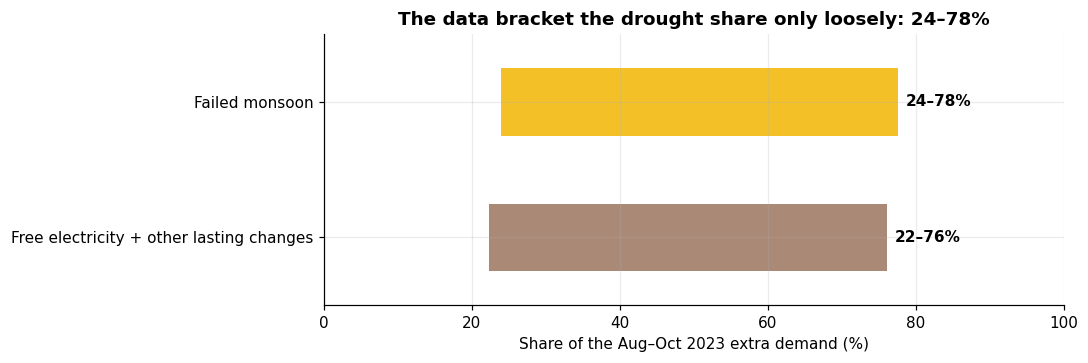

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (name, r) in enumerate(rev.iterrows()):
    c = [plots.COLORS["solar"], plots.COLORS["central_import"]][i]
    ax.barh(i, r["high %"] - r["low %"], left=r["low %"], color=c, alpha=0.85, height=0.5)
    ax.text(r["high %"] + 1, i, f"{r['low %']:.0f}–{r['high %']:.0f}%", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(range(2), rev.index); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_ylim(1.5, -0.5); ax.set_xlabel("Share of the Aug–Oct 2023 extra demand (%)")
ax.set_title(f"The data bracket the drought share only loosely: {d_lo:.0f}–{d_hi:.0f}%")
plt.tight_layout(); plots.save(fig, "07_revised_ranges"); plt.show()

### Step 4.8 — Does the `year` feature drive the result?
*Why (added after the third external review):* `year` is a model feature, and trees cannot extrapolate it, so every
prediction for 2023+ uses the "2022" leaf. Model A has no rain, so it may have learned wet 2022's lower demand as the
"2022 level" and carried it forward, inflating every excess over Model A. Re-fit all models without `year` (the trend
already handles growth) and compare.

In [13]:
CAL_NY = [c for c in F.CALENDAR_FEATURES if c != "year"]
FA_NY, FB_NY = CAL_NY + F.TEMP_FEATURES, CAL_NY + F.TEMP_FEATURES + F.RAIN_FEATURES


def evaluate_ny(mA, mB, yr):
    p = df.loc[f"{yr}-08-01":f"{yr}-10-31"].dropna(subset=["load_mw"] + FEAT_B).copy()
    a, b, y = mA.predict(p).mean(), mB.predict(p).mean(), p.load_mw.mean()
    return {"year": yr, "excess over A %": (y / a - 1) * 100, "rain effect, Model B (MW)": b - a,
            "excess over B %": (y / b - 1) * 100, "lasting, % of A expected": (y - b) / a * 100}


ny16 = [M.CounterfactualModel(f).fit(df, "2011-01-01", "2015-12-31 23:00") for f in (FA_NY, FB_NY)]
ny = [M.CounterfactualModel(f).fit(df, "2015-01-01", "2022-12-31 23:00") for f in (FA_NY, FB_NY)]
t5 = pd.DataFrame([evaluate_ny(*ny16, 2016)] + [evaluate_ny(*ny, y) for y in (2023, 2024, 2025)]).set_index("year")
ny_hi = t5.loc[2016, "excess over A %"] / t5.loc[2023, "excess over A %"] * 100
ny_lo_B = (t5.loc[2023, "excess over A %"] - t5.loc[2024, "lasting, % of A expected"]) / t5.loc[2023, "excess over A %"] * 100
print(f"Without `year`: upper end {ny_hi:.0f}%; rain-adjusted lower end {ny_lo_B:.0f}% — not reliable, because this "
      f"Model B gets the 2023 rain effect backwards")
t5.round(1)

Without `year`: upper end 88%; rain-adjusted lower end 6% — not reliable, because this Model B gets the 2023 rain effect backwards


,excess over A %,"rain effect, Model B (MW)",excess over B %,"lasting, % of A expected"
year,,,,
2016,13.3,52.4,12.4,12.5
2023,15.2,-59.5,16.0,15.9
2024,6.5,-676.8,15.6,14.4
2025,8.5,-497.3,15.2,14.3


_What I see:_ dropping `year` lowers every excess over Model A by ~5–6 points (2023: +21.5% → about +15%), which
confirms the reviewer's concern that Model A carries some of wet 2022 forward. But without `year`, Model B gives a
**negative rain effect for 2023** — it predicts *less* demand in the driest Aug–Oct in the data — so that version
of Model B is not usable for the rain-adjusted bound. Two things do not move: the **lasting increase over Model B is
+14–17% in 2023, 2024 and 2025 in both versions**, and the 2016 drought alone still produces most of 2023's excess.
**The split between the causes depends on modelling choices; the existence of both causes does not.**

### Step 4.9 — Scorecard

In [14]:
score = pd.DataFrame([
    ["Faster trend (4–8%/yr)", "\"Other\" vanishes", f"{t1.iloc[1:]['unexplained vs B (MW)'].min():,.0f}–{t1.iloc[1:]['unexplained vs B (MW)'].max():,.0f} MW remain", "Holds"],
    ["Placebo years 2015/2021/2022", "Large fake effects", f"{t2.loc[[2015, 2021, 2022], 'unexplained vs B %'].abs().max():.1f}% max (2023: {main['unexplained vs B %']:.1f}%)", "Holds"],
    ["Drop flagged days", "Numbers change", f"{t3.iloc[1]['unexplained vs B (MW)']:,.0f} vs {t3.iloc[0]['unexplained vs B (MW)']:,.0f} MW", "Holds"],
    ["2016 drought, no scheme", "Drought alone gives a similar jump", f"2016 +{ex16:.1f}% vs 2023 +{ex23:.1f}% (excess over A)", f"Upper end for drought: ~{d_hi:.0f}%"],
    ["2024 scheme, wet year (rain-adjusted)", "Lasting increase already present in 2023", f"2024 lasting +{lasting24:.1f}% vs 2023 +{ex23:.1f}% (both % of Model A expected)", f"Lower end for drought: ~{d_lo:.0f}%"],
    ["Drop the `year` feature", "Result depends on the model setup", f"upper end {ny_hi:.0f}%; lower end not computable (Model B rain effect backwards, gives {ny_lo_B:.0f}%); lasting increase stays +15–16%", "Split is model-dependent"],
    ["Evening (household) hours", "Lasting household-hour increase", f"+{eve.loc[2023]:.0f}% to +{eve.loc[2025]:.0f}% above expected in 2023–25", "Consistent with a scheme effect"],
    ["Free-electricity ≤13% estimate", "Household growth larger than reported", "Not testable with grid data", "Reference only (weak inputs)"],
], columns=["test", "would break if", "result", "verdict"])
score

,test,would break if,result,verdict
0,Faster trend (4–8%/yr),"""Other"" vanishes","816–1,276 MW remain",Holds
1,Placebo years 2015/2021/2022,Large fake effects,4.5% max (2023: 15.6%),Holds
2,Drop flagged days,Numbers change,"1,414 vs 1,414 MW",Holds
3,"2016 drought, no scheme",Drought alone gives a similar jump,2016 +16.7% vs 2023 +21.5% (excess over A),Upper end for drought: ~78%
4,"2024 scheme, wet year (rain-adjusted)",Lasting increase already present in 2023,2024 lasting +16.4% vs 2023 +21.5% (both % of ...,Lower end for drought: ~24%
5,Drop the `year` feature,Result depends on the model setup,upper end 88%; lower end not computable (Model...,Split is model-dependent
6,Evening (household) hours,Lasting household-hour increase,+10% to +13% above expected in 2023–25,Consistent with a scheme effect
7,Free-electricity ≤13% estimate,Household growth larger than reported,Not testable with grid data,Reference only (weak inputs)


## 5. Result
**Two measures — kept separate throughout:** *excess over Model A* (a model that ignores rainfall; contains the drought) and *excess over Model B* (a model that includes rainfall). For Aug–Oct 2023: **+21.5%** and **+15.6%**.

**Natural-experiment brackets (Aug–Oct)**
| Method | Drought share of 2023 excess |
|---|---|
| 2016 analogue (drought, no scheme) | **78%** (upper end) |
| 2024 comparison, rain-adjusted (same baseline) | **24%** (lower end) |
| 2025 comparison, rain-adjusted | 20% (more extra growth by then) |
| 2024, mixed baselines / raw MW | 21% / 28% — not like-for-like |
| 2024 comparison, not rain-adjusted (old method) | 43% — too high |
| Rain models (Notebooks 05–06) | ~26% (underestimate severe drought, Test 4) |

**Why the correction:** 2024 had +26% rain. Model A over-predicts in wet years, so 2024's excess over Model A (+12.3%) is the lasting increase (+16.4%, actual − Model B as % of Model A expected) *minus* a wet-weather effect (−330 MW). Using it as the lasting increase treated 2024's extra rain as part of the 2023 drought.

**Model check — drop `year`:** every excess over Model A falls by ~5–6 points (2023: +21.5% → +15.2%), so Model A does carry some of wet 2022 forward. The upper end rises to 88%. Without `year`, Model B gets the 2023 rain effect backwards, so the rain-adjusted lower end (it gives 6%) cannot be computed reliably. The **lasting increase stays at +14–17% in 2023, 2024 and 2025 in both versions.**

**Scorecard**
| Test | Would break the finding if… | Result | Verdict |
|---|---|---|---|
| Faster trend (4–8%/yr) | the unexplained part vanishes | 816–1,276 MW remain | ✅ holds |
| Placebo years 2015, 2021, 2022 | large fake effects | max ±4.5% over B (2023: +15.6%) | ✅ holds |
| Drop 8 flagged days | numbers change | 1,414 → 1,414 MW | ✅ holds |
| 2016: drought, no scheme | a drought alone gives a similar jump | +16.7% vs 2023 +21.5% | upper end for drought ~78% |
| 2024: scheme, normal rain (rain-adjusted) | the lasting increase was already present in 2023 | +16.4% remains | lower end for drought ~24% |
| Drop `year` | the result depends on model setup | upper end 88%, lower end not computable; lasting increase unchanged | split is model-dependent |
| Evening household hours | a lasting household increase exists | +10% to +13% in 2023–25 vs −12% to +7% before | fits a scheme effect |

**Revised split of the 1,860 MW excess:** failed monsoon ~24–78%; free electricity + other lasting changes ~22–76%.

Figures: `07_placebo`, `07_2016_vs_2023`, `07_revised_ranges`.

## 6. Caveats
- **The range is very wide** (24–78%). The data show that both causes were large; they cannot rank them.
- **The two ends do not fit together neatly.** If the lasting +16% was fully present in Aug–Oct 2023, almost nothing is left for the drought — yet 2016 shows a drought alone adds ~+17%. Both cannot fully hold. One possible reason: supply was rationed in Oct 2023, which capped measured load, so the two effects may not add up in the grid data.
- **The upper end relies on a 2016 model trained on 2011–2015**, years of power shortage (frequency below 49.9 Hz in 31–77% of hours in 2011–2013, ~2% in 2016), with no backtest of its own. Suppressed demand in training could inflate the 2016 excess and so the 78%. 2017 (−2.4%) is partly reassuring.
- **Model A's typical monthly error is ±7.6%** (Model B: ±4%). The brackets use Model A, so each end is uncertain by several points.
- **The split depends on modelling choices** (the `year` feature moves the brackets by 10+ points).
- The scheme cannot be separated from other lasting growth with grid data alone.
- Natural experiments and counterfactual models support, but do not prove, causation.

## 7. Next
**Communicate:** revise `reports/final_report.md` and `README.md`: the headline becomes "both causes were large; the data cannot say which was larger (drought ~24–78%)", with the corrected lower end, Model A's error, the `year` check and the 2016 training caveat.